# ***Importing Libraries***

In [1]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

SEED = 42
keras.utils.set_random_seed(SEED)

# ***Exploratory Data Analysis (EDA)***

In [2]:
url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
zip_path = keras.utils.get_file("jena_climate_2009_2016.csv.zip", origin=url)

with zipfile.ZipFile(zip_path) as z:
    z.extractall("data")

df = pd.read_csv("data/jena_climate_2009_2016.csv")
df.head()

13568290/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


In [3]:
df.tail()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
420546,31.12.2016 23:20:00,1000.07,-4.05,269.10,-8.13,73.10,4.52,3.30,1.22,2.06,3.30,1292.98,0.67,1.52,240.0
420547,31.12.2016 23:30:00,999.93,-3.35,269.81,-8.06,69.71,4.77,3.32,1.44,2.07,3.32,1289.44,1.14,1.92,234.3
420548,31.12.2016 23:40:00,999.82,-3.16,270.01,-8.21,67.91,4.84,3.28,1.55,2.05,3.28,1288.39,1.08,2.00,215.2
420549,31.12.2016 23:50:00,999.81,-4.23,268.94,-8.53,71.80,4.46,3.20,1.26,1.99,3.20,1293.56,1.49,2.16,225.8
420550,01.01.2017 00:00:00,999.82,-4.82,268.36,-8.42,75.70,4.27,3.23,1.04,2.01,3.23,1296.38,1.23,1.96,184.9


In [4]:
df.shape

(420551, 15)

In [5]:
df.columns

Index(['Date Time', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)',
       'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)',
       'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)',
       'wd (deg)'],
      dtype='object')

In [6]:
df.dtypes

,0
Date Time,object
p (mbar),float64
T (degC),float64
Tpot (K),float64
Tdew (degC),float64
rh (%),float64
VPmax (mbar),float64
VPact (mbar),float64
VPdef (mbar),float64
sh (g/kg),float64


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420551 entries, 0 to 420550
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date Time        420551 non-null  object 
 1   p (mbar)         420551 non-null  float64
 2   T (degC)         420551 non-null  float64
 3   Tpot (K)         420551 non-null  float64
 4   Tdew (degC)      420551 non-null  float64
 5   rh (%)           420551 non-null  float64
 6   VPmax (mbar)     420551 non-null  float64
 7   VPact (mbar)     420551 non-null  float64
 8   VPdef (mbar)     420551 non-null  float64
 9   sh (g/kg)        420551 non-null  float64
 10  H2OC (mmol/mol)  420551 non-null  float64
 11  rho (g/m**3)     420551 non-null  float64
 12  wv (m/s)         420551 non-null  float64
 13  max. wv (m/s)    420551 non-null  float64
 14  wd (deg)         420551 non-null  float64
dtypes: float64(14), object(1)
memory usage: 48.1+ MB


In [8]:
df.describe()

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
count,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000,420551.000000
mean,989.212776,9.450147,283.492743,4.955854,76.008259,13.576251,9.533756,4.042412,6.022408,9.640223,1216.062748,1.702224,3.056555,174.743738
std,8.358481,8.423365,8.504471,6.730674,16.476175,7.739020,4.184164,4.896851,2.656139,4.235395,39.975208,65.446714,69.016932,86.681693
min,913.600000,-23.010000,250.600000,-25.010000,12.950000,0.950000,0.790000,0.000000,0.500000,0.800000,1059.450000,-9999.000000,-9999.000000,0.000000
25%,984.200000,3.360000,277.430000,0.240000,65.210000,7.780000,6.210000,0.870000,3.920000,6.290000,1187.490000,0.990000,1.760000,124.900000
50%,989.580000,9.420000,283.470000,5.220000,79.300000,11.820000,8.860000,2.190000,5.590000,8.960000,1213.790000,1.760000,2.960000,198.100000
75%,994.720000,15.470000,289.530000,10.070000,89.400000,17.600000,12.350000,5.300000,7.800000,12.490000,1242.770000,2.860000,4.740000,234.100000
max,1015.350000,37.280000,311.340000,23.110000,100.000000,63.770000,28.320000,46.010000,18.130000,28.820000,1393.540000,28.490000,23.500000,360.000000


In [9]:
df.duplicated().sum()

np.int64(327)

In [10]:
df.isnull().sum() / df.shape[0] * 100

,0
Date Time,0.0
p (mbar),0.0
T (degC),0.0
Tpot (K),0.0
Tdew (degC),0.0
rh (%),0.0
VPmax (mbar),0.0
VPact (mbar),0.0
VPdef (mbar),0.0
sh (g/kg),0.0


In [11]:
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
df['Date Time'].diff().value_counts().head()

,count
Date Time,
0 days 00:10:00,420543
0 days 00:20:00,2
0 days 00:30:00,1
-1 days +00:10:00,1
-2 days +17:40:00,1


In [12]:
df[['wv (m/s)', 'max. wv (m/s)']].min()

,0
wv (m/s),-9999.0
max. wv (m/s),-9999.0


In [13]:
df.loc[df['wv (m/s)'] == -9999.0, 'wv (m/s)'] = 0.0
df.loc[df['max. wv (m/s)'] == -9999.0, 'max. wv (m/s)'] = 0.0
df[['wv (m/s)', 'max. wv (m/s)']].min()

,0
wv (m/s),0.0
max. wv (m/s),0.0


# ***Data Visualization***

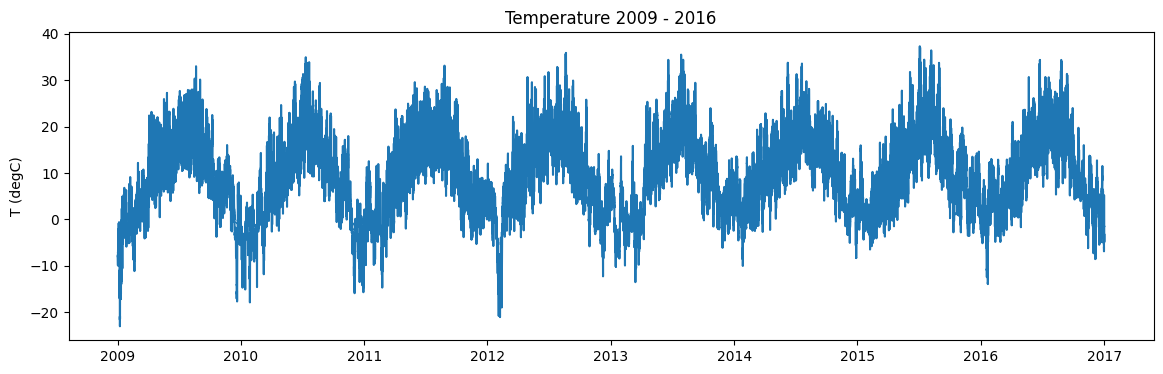

In [14]:
plt.figure(figsize=(14, 4))
plt.plot(df['Date Time'], df['T (degC)'])
plt.title('Temperature 2009 - 2016')
plt.ylabel('T (degC)')
plt.show()

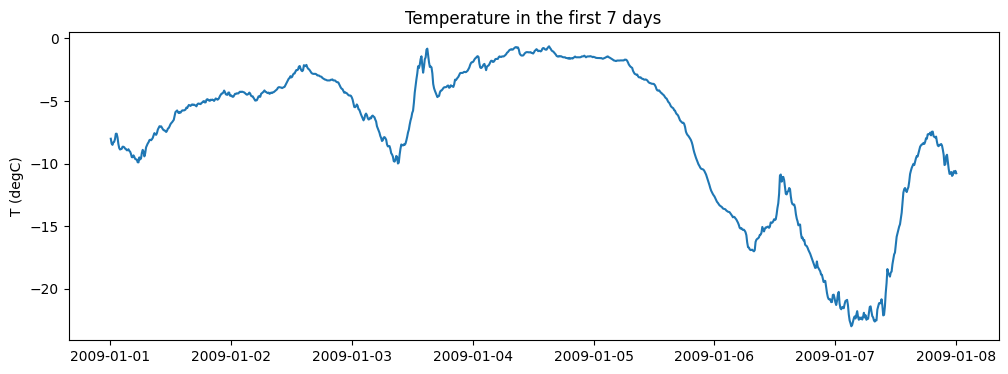

In [15]:
plt.figure(figsize=(12, 4))
plt.plot(df['Date Time'][:1008], df['T (degC)'][:1008])
plt.title('Temperature in the first 7 days')
plt.ylabel('T (degC)')
plt.show()

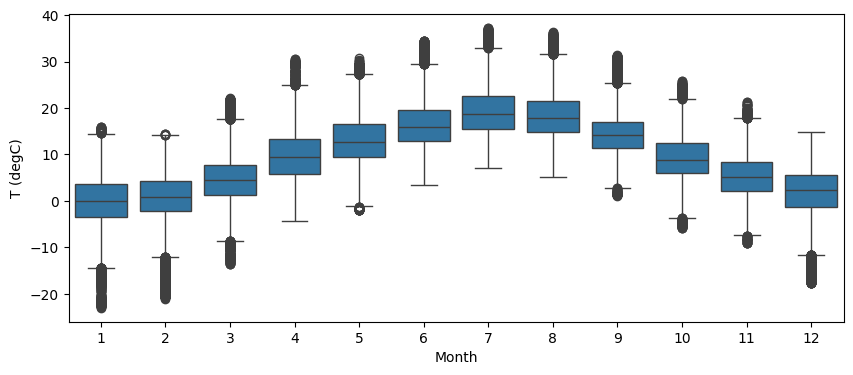

In [16]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Date Time'].dt.month, y=df['T (degC)'])
plt.xlabel('Month')
plt.show()

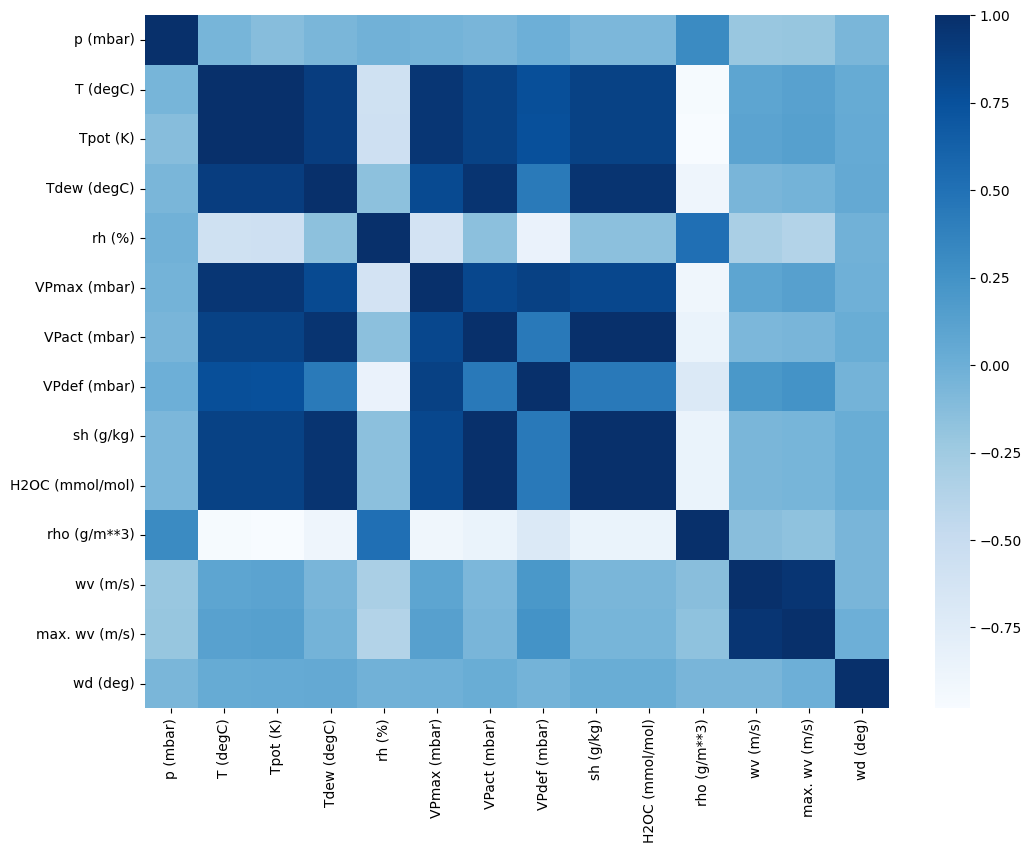

In [17]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.drop(columns=['Date Time']).corr(), cmap='Blues')
plt.show()

# ***Data Preprocessing***

In [18]:
df = df[5::6].reset_index(drop=True)
df.shape

(70091, 15)

In [19]:
features = df.columns.drop('Date Time')
data = df[features].values.astype('float32')
temp_idx = list(features).index('T (degC)')
data.shape

(70091, 14)

In [20]:
train_rows = int(len(data) * 0.7)

mean = data[:train_rows].mean(axis=0)
std = data[:train_rows].std(axis=0)

data = (data - mean) / std

In [21]:
window = 72
horizon = 24

X, y = [], []
for i in range(len(data) - window - horizon):
    X.append(data[i:i + window])
    y.append(data[i + window + horizon - 1, temp_idx])

X = np.array(X)
y = np.array(y)
print(X.shape, y.shape)

(69995, 72, 14) (69995,)


In [22]:
n = len(X)
train_end = int(n * 0.7)
val_end = int(n * 0.85)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]
print(X_train.shape, X_val.shape, X_test.shape)

(48996, 72, 14) (10499, 72, 14) (10500, 72, 14)


In [23]:
temp_mean = mean[temp_idx]
temp_std = std[temp_idx]

y_test_c = y_test * temp_std + temp_mean

# ***Naive Baseline***

In [24]:
y_pred_naive = X_test[:, -1, temp_idx] * temp_std + temp_mean

print("MAE:", mean_absolute_error(y_test_c, y_pred_naive))
print("RMSE:", np.sqrt(mean_squared_error(y_test_c, y_pred_naive)))

MAE: 2.4972314834594727
RMSE: 3.2475772043261855


# ***Simple RNN Model***

In [25]:
rnn_model = keras.Sequential([
    layers.Input(shape=(window, X.shape[2])),
    layers.SimpleRNN(64),
    layers.Dense(1)
])

rnn_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         5,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

rnn_history = rnn_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=256, callbacks=[early_stop], verbose=2)

Epoch 1/20
192/192 - 7s - 36ms/step - loss: 0.1861 - mae: 0.3306 - val_loss: 0.1443 - val_mae: 0.2948
Epoch 2/20
192/192 - 2s - 9ms/step - loss: 0.1430 - mae: 0.2944 - val_loss: 0.1389 - val_mae: 0.2905
Epoch 3/20
192/192 - 2s - 13ms/step - loss: 0.1380 - mae: 0.2893 - val_loss: 0.1382 - val_mae: 0.2904
Epoch 4/20
192/192 - 2s - 9ms/step - loss: 0.1344 - mae: 0.2856 - val_loss: 0.1399 - val_mae: 0.2926
Epoch 5/20
192/192 - 2s - 10ms/step - loss: 0.1314 - mae: 0.2823 - val_loss: 0.1368 - val_mae: 0.2899
Epoch 6/20
192/192 - 2s - 8ms/step - loss: 0.1290 - mae: 0.2797 - val_loss: 0.1372 - val_mae: 0.2903
Epoch 7/20
192/192 - 2s - 8ms/step - loss: 0.1264 - mae: 0.2768 - val_loss: 0.1406 - val_mae: 0.2942
Epoch 8/20
192/192 - 2s - 8ms/step - loss: 0.1264 - mae: 0.2766 - val_loss: 0.1431 - val_mae: 0.2952


# ***LSTM Model***

In [27]:
lstm_model = keras.Sequential([
    layers.Input(shape=(window, X.shape[2])),
    layers.LSTM(64),
    layers.Dropout(0.2),
    layers.Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,289 (79.25 KB)

 Trainable params: 20,289 (79.25 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

lstm_history = lstm_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=256, callbacks=[early_stop], verbose=2)

Epoch 1/20
192/192 - 5s - 28ms/step - loss: 0.1885 - mae: 0.3343 - val_loss: 0.1403 - val_mae: 0.2901
Epoch 2/20
192/192 - 2s - 11ms/step - loss: 0.1435 - mae: 0.2955 - val_loss: 0.1327 - val_mae: 0.2823
Epoch 3/20
192/192 - 1s - 8ms/step - loss: 0.1331 - mae: 0.2849 - val_loss: 0.1317 - val_mae: 0.2810
Epoch 4/20
192/192 - 1s - 8ms/step - loss: 0.1276 - mae: 0.2791 - val_loss: 0.1311 - val_mae: 0.2811
Epoch 5/20
192/192 - 1s - 8ms/step - loss: 0.1219 - mae: 0.2731 - val_loss: 0.1308 - val_mae: 0.2811
Epoch 6/20
192/192 - 1s - 8ms/step - loss: 0.1162 - mae: 0.2664 - val_loss: 0.1328 - val_mae: 0.2838
Epoch 7/20
192/192 - 2s - 8ms/step - loss: 0.1113 - mae: 0.2614 - val_loss: 0.1364 - val_mae: 0.2873
Epoch 8/20
192/192 - 1s - 8ms/step - loss: 0.1065 - mae: 0.2553 - val_loss: 0.1386 - val_mae: 0.2897


# ***GRU Model***

In [29]:
gru_model = keras.Sequential([
    layers.Input(shape=(window, X.shape[2])),
    layers.GRU(64),
    layers.Dropout(0.2),
    layers.Dense(1)
])

gru_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        15,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,425 (60.25 KB)

 Trainable params: 15,425 (60.25 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

gru_history = gru_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=256, callbacks=[early_stop], verbose=2)

Epoch 1/20
192/192 - 4s - 18ms/step - loss: 0.2080 - mae: 0.3488 - val_loss: 0.1388 - val_mae: 0.2895
Epoch 2/20
192/192 - 1s - 8ms/step - loss: 0.1511 - mae: 0.3028 - val_loss: 0.1355 - val_mae: 0.2847
Epoch 3/20
192/192 - 1s - 7ms/step - loss: 0.1418 - mae: 0.2932 - val_loss: 0.1332 - val_mae: 0.2827
Epoch 4/20
192/192 - 1s - 7ms/step - loss: 0.1363 - mae: 0.2875 - val_loss: 0.1317 - val_mae: 0.2809
Epoch 5/20
192/192 - 1s - 7ms/step - loss: 0.1326 - mae: 0.2832 - val_loss: 0.1294 - val_mae: 0.2799
Epoch 6/20
192/192 - 1s - 7ms/step - loss: 0.1295 - mae: 0.2800 - val_loss: 0.1275 - val_mae: 0.2773
Epoch 7/20
192/192 - 3s - 14ms/step - loss: 0.1261 - mae: 0.2762 - val_loss: 0.1266 - val_mae: 0.2761
Epoch 8/20
192/192 - 2s - 11ms/step - loss: 0.1230 - mae: 0.2733 - val_loss: 0.1248 - val_mae: 0.2738
Epoch 9/20
192/192 - 1s - 8ms/step - loss: 0.1191 - mae: 0.2690 - val_loss: 0.1252 - val_mae: 0.2742
Epoch 10/20
192/192 - 1s - 7ms/step - loss: 0.1164 - mae: 0.2662 - val_loss: 0.1263 - va

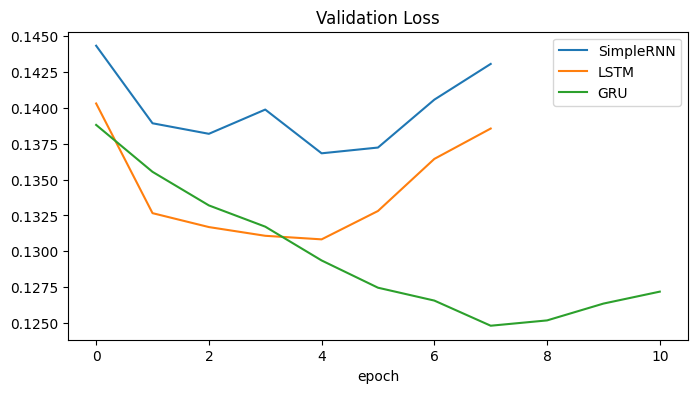

In [31]:
plt.figure(figsize=(8, 4))
plt.plot(rnn_history.history['val_loss'], label='SimpleRNN')
plt.plot(lstm_history.history['val_loss'], label='LSTM')
plt.plot(gru_history.history['val_loss'], label='GRU')
plt.title('Validation Loss')
plt.xlabel('epoch')
plt.legend()
plt.show()

# ***Evaluating the LSTM***

In [32]:
y_pred_lstm = lstm_model.predict(X_test, verbose=0).ravel() * temp_std + temp_mean

print("MAE:", mean_absolute_error(y_test_c, y_pred_lstm))
print("RMSE:", np.sqrt(mean_squared_error(y_test_c, y_pred_lstm)))
print("R2:", r2_score(y_test_c, y_pred_lstm))

MAE: 2.304690361022949
RMSE: 2.942891793172702
R2: 0.8569966554641724


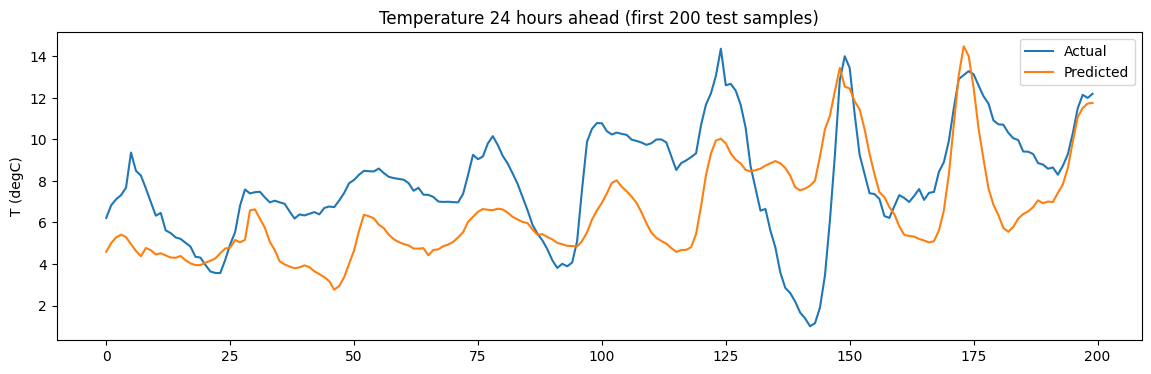

In [33]:
plt.figure(figsize=(14, 4))
plt.plot(y_test_c[:200], label='Actual')
plt.plot(y_pred_lstm[:200], label='Predicted')
plt.title('Temperature 24 hours ahead (first 200 test samples)')
plt.ylabel('T (degC)')
plt.legend()
plt.show()

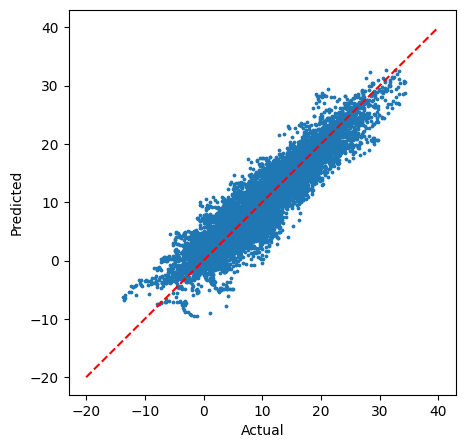

In [34]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test_c, y_pred_lstm, s=3)
plt.plot([-20, 40], [-20, 40], 'r--')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

# ***Model Comparison***

In [35]:
y_pred_rnn = rnn_model.predict(X_test, verbose=0).ravel() * temp_std + temp_mean
y_pred_gru = gru_model.predict(X_test, verbose=0).ravel() * temp_std + temp_mean

results = []
for name, y_pred in [("Naive", y_pred_naive), ("SimpleRNN", y_pred_rnn), ("LSTM", y_pred_lstm), ("GRU", y_pred_gru)]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_c, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_c, y_pred)),
        "R2": r2_score(y_test_c, y_pred)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="RMSE")
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,MAE,RMSE,R2
0,GRU,2.262655,2.901166,0.861023
1,LSTM,2.304690,2.942892,0.856997
2,SimpleRNN,2.391109,3.070842,0.844291
3,Naive,2.497231,3.247577,0.825853


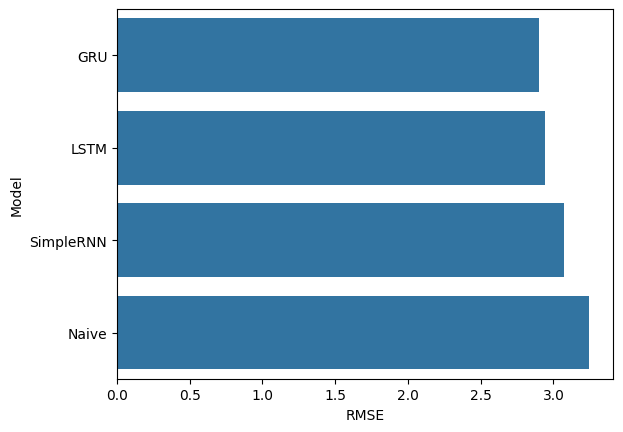

In [36]:
sns.barplot(x="RMSE", y="Model", data=results_df)
plt.show()